# 04 – Baseline ML truyền thống (TF-IDF + LR / SVM / NB)

Mục tiêu: dựng mốc so sánh cho BiLSTM và PhoBERT trên UIT-VSFC (3 lớp negative / neutral / positive), metric chính Macro-F1.

Quy tắc xuyên suốt notebook:
- Chọn mô hình và siêu tham số **chỉ dựa trên tập dev**.
- Tập **test chỉ chấm một lần**, ở ô 8, sau khi đã chốt mô hình.
- Mọi bảng và ma trận nhầm lẫn dùng cùng thứ tự lớp: negative, neutral, positive.

## Ô 1. Nạp dữ liệu và kiểm tra

Đọc `data_clean.csv` (đầu ra của notebook 03), kiểm tra cột, câu rỗng, nhãn, kích thước từng tập và phân bố lớp. Các `assert` ở đây là chốt chặn: nếu dữ liệu bị lệch so với notebook 03 thì dừng ngay, không để lỗi lan sang các ô sau. Lớp neutral rất ít (khoảng 4%) nên F1 của lớp này sẽ dao động mạnh, cần lưu ý khi đọc kết quả.

In [12]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, json
import numpy as np
import pandas as pd

PROJECT     = '/content/drive/MyDrive/project1_vsfc'
DATA_DIR    = f'{PROJECT}/data'
RESULTS_DIR = f'{PROJECT}/results'
os.makedirs(RESULTS_DIR, exist_ok=True)

SEED    = 42
LABELS  = ['negative', 'neutral', 'positive']     # thứ tự cố định cho mọi bảng và ma trận nhầm lẫn
ID2NAME = {0: 'negative', 1: 'neutral', 2: 'positive'}

df = pd.read_csv(f'{DATA_DIR}/data_clean.csv', encoding='utf-8-sig', keep_default_na=False)
print('Kích thước:', df.shape)
print('Các cột:', df.columns.tolist())

# 1. Kiểm tra cứng
need = ['split', 'text_raw', 'text_clean', 'text_seg', 'sentiment', 'sentiment_name']
missing = [c for c in need if c not in df.columns]
assert not missing, f'Thiếu cột: {missing}'

for c in ['text_raw', 'text_clean', 'text_seg']:
    assert (df[c].str.strip() != '').all(), f'Cột {c} có câu rỗng'

assert set(df['split']) == {'train', 'dev', 'test'}, 'Tên split không đúng'
assert set(df['sentiment_name']) == set(LABELS), 'Nhãn chữ không đúng'
assert (df['sentiment_name'] == df['sentiment'].map(ID2NAME)).all(), 'Nhãn số và nhãn chữ không khớp'

expected = {'train': 11426, 'dev': 1583, 'test': 3166}
assert df['split'].value_counts().to_dict() == expected, 'Kích thước split khác notebook 03'
print('\nCác kiểm tra cơ bản: đạt')

# 2. Tách 3 tập
tr = df[df['split'] == 'train'].reset_index(drop=True)
dv = df[df['split'] == 'dev'].reset_index(drop=True)
te = df[df['split'] == 'test'].reset_index(drop=True)

y_tr, y_dv, y_te = tr['sentiment'].values, dv['sentiment'].values, te['sentiment'].values

# 3. Phân bố lớp theo từng tập
cnt = pd.crosstab(df['split'], df['sentiment_name'])[LABELS].loc[['train', 'dev', 'test']]
pct = (cnt.div(cnt.sum(axis=1), axis=0) * 100).round(1)
print('\nSố câu theo lớp:');  print(cnt)
print('\nTỉ lệ (%) theo lớp:'); print(pct)
print(f"\nSố câu neutral trong dev: {cnt.loc['dev', 'neutral']}, trong test: {cnt.loc['test', 'neutral']}")

# 4. Xem nhanh vài dòng
print()
print(tr[['text_clean', 'text_seg', 'sentiment_name']].sample(3, random_state=SEED).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kích thước: (16175, 6)
Các cột: ['split', 'text_raw', 'text_clean', 'text_seg', 'sentiment', 'sentiment_name']

Các kiểm tra cơ bản: đạt

Số câu theo lớp:
sentiment_name  negative  neutral  positive
split                                      
train               5325      458      5643
dev                  705       73       805
test                1409      167      1590

Tỉ lệ (%) theo lớp:
sentiment_name  negative  neutral  positive
split                                      
train               46.6      4.0      49.4
dev                 44.5      4.6      50.9
test                44.5      5.3      50.2

Số câu neutral trong dev: 73, trong test: 167

                                                                                                                                      text_clean                                                               

## Ô 2. Hàm đánh giá chung

Định nghĩa một lần, dùng cho mọi mô hình ở các ô sau để số liệu so sánh được với nhau:

- `evaluate`: trả về Macro-F1 (metric chính), Accuracy, và Precision / Recall / F1 từng lớp.
- `show_report`: in báo cáo chi tiết theo từng lớp.
- `plot_cm`: vẽ ma trận nhầm lẫn (số câu và tỉ lệ theo hàng), thứ tự lớp cố định.
- `log_result`: gom kết quả của mọi cấu hình vào một danh sách để làm bảng tổng hợp ở ô 9.

Để kiểm tra hàm, chạy thử với hai trường hợp biết trước đáp án: TH1 : dự đoán hoàn hảo (Macro-F1 phải bằng 1), TH2 : luôn đoán lớp positive (mốc sàn, Macro-F1 phải rất thấp). Mốc sàn này cho thấy Accuracy một mình dễ gây hiểu nhầm trên dữ liệu lệch lớp.

Luôn đoán positive trên dev:
  Accuracy = 0.5085 | Macro-F1 = 0.2247
              precision    recall  f1-score   support

    negative     0.0000    0.0000    0.0000       705
     neutral     0.0000    0.0000    0.0000        73
    positive     0.5085    1.0000    0.6742       805

    accuracy                         0.5085      1583
   macro avg     0.1695    0.3333    0.2247      1583
weighted avg     0.2586    0.5085    0.3429      1583



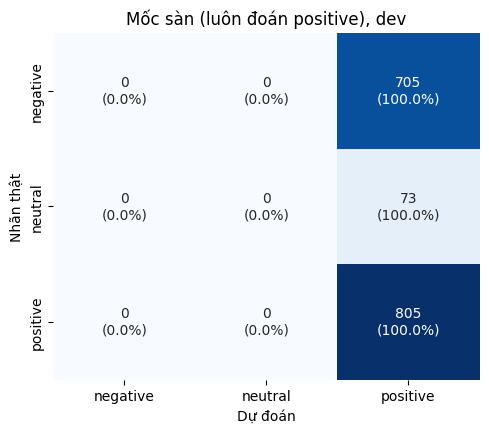

Hàm đánh giá hoạt động đúng.


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

LABEL_IDS = [0, 1, 2]          # tương ứng LABELS = negative, neutral, positive
RESULTS = []                   # gom kết quả mọi cấu hình, dùng cho bảng tổng hợp ở ô 9

def evaluate(y_true, y_pred, name='', split=''):
    """Trả về dict số liệu: Macro-F1 (chính), Accuracy, P/R/F1 từng lớp."""
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABEL_IDS, zero_division=0)
    row = {'model': name, 'split': split,
           'macro_f1': f1_score(y_true, y_pred, average='macro', labels=LABEL_IDS, zero_division=0),
           'accuracy': accuracy_score(y_true, y_pred)}
    for i, lab in enumerate(LABELS):
        row[f'P_{lab}'], row[f'R_{lab}'], row[f'F1_{lab}'] = p[i], r[i], f[i]
    return row

def log_result(row, **extra):
    """Thêm một kết quả vào RESULTS (extra: tham số, thời gian chạy, ...)."""
    RESULTS.append({**row, **extra})
    return row

def show_report(y_true, y_pred):
    print(classification_report(y_true, y_pred, labels=LABEL_IDS,
                                target_names=LABELS, digits=4, zero_division=0))

def plot_cm(y_true, y_pred, title='', path=None):
    """Ma trận nhầm lẫn: số câu (trên) và tỉ lệ % theo hàng (dưới, hàng = nhãn thật)."""
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_IDS)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i, j]}\n({cm_pct[i, j]:.1f}%)' for j in range(3)] for i in range(3)])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False,
                xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel('Dự đoán'); plt.ylabel('Nhãn thật'); plt.title(title)
    if path:
        plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()

# ---- Kiểm tra hàm bằng 2 trường hợp biết trước đáp án ----
perfect = evaluate(y_dv, y_dv, 'perfect', 'dev')
assert abs(perfect['macro_f1'] - 1) < 1e-9 and abs(perfect['accuracy'] - 1) < 1e-9

majority = evaluate(y_dv, np.full_like(y_dv, 2), 'always-positive', 'dev')   # luôn đoán positive
print('Luôn đoán positive trên dev:')
print(f"  Accuracy = {majority['accuracy']:.4f} | Macro-F1 = {majority['macro_f1']:.4f}")
show_report(y_dv, np.full_like(y_dv, 2))
plot_cm(y_dv, np.full_like(y_dv, 2), 'Mốc sàn (luôn đoán positive), dev')
print('Hàm đánh giá hoạt động đúng.')

## Ô 3. Mốc: TF-IDF + Logistic Regression

Mô hình đơn giản nhất làm điểm xuất phát: TF-IDF trên từ đơn (unigram) của `text_clean`, phân loại bằng Logistic Regression. Mọi cấu hình ở các ô sau sẽ so với mốc này.

Hai điểm cần giữ đúng:
- Bộ vector hóa và bộ phân loại bọc trong một `Pipeline`, chỉ `fit` trên **train**, nên từ vựng và IDF không bị rò rỉ từ dev/test.
- `token_pattern` giữ cả từ một ký tự ("k", "ạ", "ô") và bỏ dấu câu; các từ phủ định ("không", "chưa") và từ chỉ mức độ ("rất") được giữ nguyên, không bỏ stopword.

So sánh hai biến thể về trọng số lớp, vì neutral chỉ chiếm ~4%:
1. Không dùng class weight.
2. `class_weight='balanced'` (lớp ít được phạt nặng hơn khi đoán sai).

Chỉ chấm trên **dev**. Hàm `run_sk` được định nghĩa ở đây để tái sử dụng ở các ô 4 đến 7.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

TOKEN = r'(?u)\b\w+\b'      # giữ cả từ 1 ký tự, bỏ dấu câu

def run_sk(name, vec, clf, text_col='text_clean', verbose=True, **extra):
    """Fit trên train, chấm trên dev, ghi vào RESULTS. Trả về (pipeline, dòng kết quả)."""
    pipe = Pipeline([('vec', vec), ('clf', clf)])
    t0 = time.time()
    pipe.fit(tr[text_col], y_tr)
    fit_s = time.time() - t0
    pred = pipe.predict(dv[text_col])
    row = evaluate(y_dv, pred, name, 'dev')
    log_result(row, text_col=text_col, fit_sec=round(fit_s, 1), **extra)
    if verbose:
        print(f"{name:35s} Macro-F1 = {row['macro_f1']:.4f} | Acc = {row['accuracy']:.4f} "
              f"| F1 neutral = {row['F1_neutral']:.4f} | fit {fit_s:.1f}s")
    return pipe, row

def make_vec(**kw):
    base = dict(token_pattern=TOKEN, lowercase=True, sublinear_tf=True, min_df=2)
    base.update(kw)
    return TfidfVectorizer(**base)

def make_lr(cw=None, C=1.0):
    return LogisticRegression(C=C, class_weight=cw, max_iter=2000, random_state=SEED)

# --- Mốc: unigram, text_clean ---
pipes = {}
pipes['LR'],          r1 = run_sk('TFIDF-uni + LR',          make_vec(ngram_range=(1, 1)), make_lr(None),
                                  model_family='LR', ngram='word(1,1)', class_weight='none')
pipes['LR-balanced'], r2 = run_sk('TFIDF-uni + LR (balanced)', make_vec(ngram_range=(1, 1)), make_lr('balanced'),
                                  model_family='LR', ngram='word(1,1)', class_weight='balanced')

print('\nKích thước từ vựng:', len(pipes['LR'].named_steps['vec'].vocabulary_))

# --- Báo cáo chi tiết từng lớp trên dev ---
for key in ['LR', 'LR-balanced']:
    print(f'\n=== {key} (dev) ===')
    show_report(y_dv, pipes[key].predict(dv['text_clean']))

# --- Kiểm tra nhanh: từ có hệ số lớn nhất mỗi lớp (bản balanced) ---
vec = pipes['LR-balanced'].named_steps['vec']
clf = pipes['LR-balanced'].named_steps['clf']
vocab = np.array(vec.get_feature_names_out())
print('\nTop 10 từ theo hệ số của từng lớp (LR balanced):')
for i, lab in enumerate(LABELS):
    top = vocab[np.argsort(clf.coef_[i])[::-1][:10]]
    print(f'  {lab:9s}:', ', '.join(top))

TFIDF-uni + LR                      Macro-F1 = 0.7023 | Acc = 0.9078 | F1 neutral = 0.2558 | fit 0.3s
TFIDF-uni + LR (balanced)           Macro-F1 = 0.7182 | Acc = 0.8490 | F1 neutral = 0.3704 | fit 1.0s

Kích thước từ vựng: 1484

=== LR (dev) ===
              precision    recall  f1-score   support

    negative     0.8862    0.9504    0.9172       705
     neutral     0.8462    0.1507    0.2558        73
    positive     0.9287    0.9391    0.9339       805

    accuracy                         0.9078      1583
   macro avg     0.8870    0.6801    0.7023      1583
weighted avg     0.9060    0.9078    0.8952      1583


=== LR-balanced (dev) ===
              precision    recall  f1-score   support

    negative     0.9088    0.8340    0.8698       705
     neutral     0.2538    0.6849    0.3704        73
    positive     0.9553    0.8770    0.9145       805

    accuracy                         0.8490      1583
   macro avg     0.7060    0.7987    0.7182      1583
weighted avg     0

## Ô 4. Thêm SVM và Naive Bayes

Giữ nguyên đầu vào của mốc (TF-IDF unigram trên `text_clean`) để chỉ thay đổi **bộ phân loại**, từ đó so sánh công bằng với LR ở ô 3.

- **Linear SVM (`LinearSVC`)**: thường mạnh nhất trên văn bản TF-IDF. Chạy có và không `class_weight='balanced'`.
- **Naive Bayes**: nhanh, hay dùng làm mốc cho văn bản. Naive Bayes không có `class_weight`, nên dùng hai cách tương đương:
  - `MultinomialNB(fit_prior=False)`: bỏ prior theo tần suất lớp, coi các lớp như nhau.
  - `ComplementNB`: biến thể thiết kế cho dữ liệu lệch lớp.
  - `MultinomialNB` mặc định để đối chiếu.

Tất cả dùng tham số mặc định hợp lý (`C=1`, `alpha=1`), chưa tinh chỉnh; tinh chỉnh nhỏ trên dev để dành cho ô 7. Chỉ chấm trên **dev**. Cuối ô in bảng gộp mọi cấu hình đã chạy (gồm mốc LR ở ô 3), xếp theo Macro-F1 kèm Precision/Recall của neutral để thấy mô hình nào đang đánh đổi như thế nào.

In [15]:
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB

def make_svm(cw=None, C=1.0):
    return LinearSVC(C=C, class_weight=cw, max_iter=5000, random_state=SEED)

uni = dict(ngram_range=(1, 1))

# --- Linear SVM ---
pipes['SVM'],          _ = run_sk('TFIDF-uni + SVM',            make_vec(**uni), make_svm(None),
                                  model_family='SVM', ngram='word(1,1)', class_weight='none')
pipes['SVM-balanced'], _ = run_sk('TFIDF-uni + SVM (balanced)', make_vec(**uni), make_svm('balanced'),
                                  model_family='SVM', ngram='word(1,1)', class_weight='balanced')

# --- Naive Bayes ---
pipes['NB'],           _ = run_sk('TFIDF-uni + MultinomialNB',               make_vec(**uni), MultinomialNB(alpha=1.0),
                                  model_family='NB', ngram='word(1,1)', class_weight='none')
pipes['NB-noprior'],   _ = run_sk('TFIDF-uni + MultinomialNB (fit_prior=F)', make_vec(**uni), MultinomialNB(alpha=1.0, fit_prior=False),
                                  model_family='NB', ngram='word(1,1)', class_weight='uniform-prior')
pipes['CNB'],          _ = run_sk('TFIDF-uni + ComplementNB',                make_vec(**uni), ComplementNB(alpha=1.0),
                                  model_family='NB', ngram='word(1,1)', class_weight='complement')

# --- Bảng gộp tất cả cấu hình đã chạy trên dev ---
res = pd.DataFrame(RESULTS)
res = res[res['split'] == 'dev']
cols = ['model', 'macro_f1', 'accuracy', 'P_neutral', 'R_neutral', 'F1_neutral',
        'F1_negative', 'F1_positive', 'fit_sec']
print('\nTất cả cấu hình trên dev, xếp theo Macro-F1:')
print(res[cols].sort_values('macro_f1', ascending=False).round(4).to_string(index=False))

# --- Báo cáo chi tiết của mô hình mới tốt nhất ---
new = res[res['model'].str.contains('SVM|NB')].sort_values('macro_f1', ascending=False)
best_name = new.iloc[0]['model']
key = {'TFIDF-uni + SVM': 'SVM', 'TFIDF-uni + SVM (balanced)': 'SVM-balanced',
       'TFIDF-uni + MultinomialNB': 'NB', 'TFIDF-uni + MultinomialNB (fit_prior=F)': 'NB-noprior',
       'TFIDF-uni + ComplementNB': 'CNB'}[best_name]
print(f'\n=== Mô hình mới tốt nhất: {best_name} (dev) ===')
show_report(y_dv, pipes[key].predict(dv['text_clean']))


TFIDF-uni + SVM                     Macro-F1 = 0.7072 | Acc = 0.9059 | F1 neutral = 0.2708 | fit 0.8s
TFIDF-uni + SVM (balanced)          Macro-F1 = 0.7604 | Acc = 0.8958 | F1 neutral = 0.4358 | fit 0.8s
TFIDF-uni + MultinomialNB           Macro-F1 = 0.5863 | Acc = 0.8591 | F1 neutral = 0.0000 | fit 0.4s
TFIDF-uni + MultinomialNB (fit_prior=F) Macro-F1 = 0.6705 | Acc = 0.8351 | F1 neutral = 0.2822 | fit 0.3s
TFIDF-uni + ComplementNB            Macro-F1 = 0.6083 | Acc = 0.8553 | F1 neutral = 0.0732 | fit 0.3s

Tất cả cấu hình trên dev, xếp theo Macro-F1:
                                  model  macro_f1  accuracy  P_neutral  R_neutral  F1_neutral  F1_negative  F1_positive  fit_sec
             TFIDF-uni + SVM (balanced)    0.7604    0.8958     0.3679     0.5342      0.4358       0.9116       0.9338      0.8
              TFIDF-uni + LR (balanced)    0.7182    0.8490     0.2538     0.6849      0.3704       0.8698       0.9145      1.0
                        TFIDF-uni + SVM    0.7072    

In [16]:
def log_result(row, **extra):
    """Ghi kết quả; nếu cùng (model, split) đã có thì thay bằng bản mới."""
    global RESULTS
    new = {**row, **extra}
    RESULTS = [r for r in RESULTS if not (r['model'] == new['model'] and r['split'] == new['split'])]
    RESULTS.append(new)
    return row

_seen = {}
for r in RESULTS:
    _seen[(r['model'], r['split'])] = r
RESULTS = list(_seen.values())
print(len(RESULTS), 'cấu hình')

7 cấu hình


## Ô 5. Word n-gram và char n-gram

Giữ nguyên `text_clean` và chỉ thay **cách trích đặc trưng**, để xem thông tin về cụm từ và ký tự có giúp hay không. Mỗi bộ đặc trưng chạy với hai bộ phân loại tốt nhất ở ô 3 và ô 4 (SVM balanced và LR balanced), vì nếu một kiểu đặc trưng thật sự tốt hơn thì nó phải tốt hơn ở cả hai.

| Đặc trưng | Ý nghĩa |
|---|---|
| `word(1,1)` | Mốc ở các ô trước (chạy lại để kiểm tra khớp 0,7604 của ô 4) |
| `word(1,2)` | Thêm cặp từ: bắt cụm như "không nhiệt tình", "cảm ơn" |
| `word(1,3)` | Thêm bộ ba từ |
| `char_wb(2,5)` | N-gram ký tự trong từng từ: chịu được lỗi chính tả, viết tắt, biến thể dấu |
| `word(1,2) + char_wb(2,5)` | Ghép hai loại |

Nhắc lại ngưỡng đọc kết quả: neutral dev chỉ có 73 câu, nên chênh dưới khoảng 0,01 Macro-F1 coi như ngang nhau. Nếu nhiều đặc trưng ngang nhau thì ưu tiên cái đơn giản hơn (ít chiều hơn, nhanh hơn). Chỉ chấm trên **dev**. Các hàm tạo đặc trưng được lưu trong `FEATS` để ô 6 và ô 7 dùng lại.

In [17]:
from sklearn.pipeline import FeatureUnion

def _char(ng, analyzer='char_wb'):
    return TfidfVectorizer(analyzer=analyzer, ngram_range=ng, lowercase=True,
                           sublinear_tf=True, min_df=2)

FEATS = {
    'word(1,1)':               lambda: make_vec(ngram_range=(1, 1)),
    'word(1,2)':               lambda: make_vec(ngram_range=(1, 2)),
    'word(1,3)':               lambda: make_vec(ngram_range=(1, 3)),
    'char_wb(2,5)':            lambda: _char((2, 5)),
    'word(1,2)+char_wb(2,5)':  lambda: FeatureUnion([('w', make_vec(ngram_range=(1, 2))),
                                                      ('c', _char((2, 5)))]),
}
CLFS = {
    'SVM-bal': lambda: make_svm('balanced'),
    'LR-bal':  lambda: make_lr('balanced'),
}

for feat, mk_vec in FEATS.items():
    for cname, mk_clf in CLFS.items():
        pipe, row = run_sk(f'{feat} + {cname}', mk_vec(), mk_clf(), text_col='text_clean',
                           model_family=cname, ngram=feat, class_weight='balanced',
                           feat=feat, clf_name=cname, stage='o5')
        pipes[f'{feat} + {cname}'] = pipe
    n_feat = len(pipes[f'{feat} + SVM-bal'].named_steps['vec'].get_feature_names_out())
    print(f'   -> {feat}: {n_feat:,} đặc trưng\n')

# --- Bảng so sánh ---
r5 = pd.DataFrame([r for r in RESULTS if r.get('stage') == 'o5'])
tab = r5.pivot(index='feat', columns='clf_name', values='macro_f1').loc[list(FEATS)]
tab_neu = r5.pivot(index='feat', columns='clf_name', values='F1_neutral').loc[list(FEATS)]
out = pd.concat({'Macro-F1': tab, 'F1 neutral': tab_neu}, axis=1).round(4)
print('Bảng so sánh đặc trưng trên dev:')
print(out.to_string())

base = tab.loc['word(1,1)']
print('\nChênh Macro-F1 so với word(1,1):')
print((tab - base).round(4).to_string())
print(f"\nKiểm tra khớp ô 4: word(1,1) + SVM-bal = {tab.loc['word(1,1)', 'SVM-bal']:.4f} (kỳ vọng 0.7604)")

# --- Đặc trưng tốt nhất theo SVM-bal ---
BEST_FEAT_O5 = tab['SVM-bal'].idxmax()
print(f"\nĐặc trưng tốt nhất theo SVM-bal: {BEST_FEAT_O5} ({tab['SVM-bal'].max():.4f})")
print('\nBáo cáo chi tiết (dev):')
show_report(y_dv, pipes[f'{BEST_FEAT_O5} + SVM-bal'].predict(dv['text_clean']))

word(1,1) + SVM-bal                 Macro-F1 = 0.7604 | Acc = 0.8958 | F1 neutral = 0.4358 | fit 0.5s
word(1,1) + LR-bal                  Macro-F1 = 0.7182 | Acc = 0.8490 | F1 neutral = 0.3704 | fit 0.7s
   -> word(1,1): 1,484 đặc trưng

word(1,2) + SVM-bal                 Macro-F1 = 0.7723 | Acc = 0.9128 | F1 neutral = 0.4531 | fit 0.8s
word(1,2) + LR-bal                  Macro-F1 = 0.7504 | Acc = 0.8812 | F1 neutral = 0.4308 | fit 3.8s
   -> word(1,2): 13,282 đặc trưng

word(1,3) + SVM-bal                 Macro-F1 = 0.7627 | Acc = 0.9122 | F1 neutral = 0.4274 | fit 1.5s
word(1,3) + LR-bal                  Macro-F1 = 0.7507 | Acc = 0.8831 | F1 neutral = 0.4343 | fit 6.1s
   -> word(1,3): 26,705 đặc trưng

char_wb(2,5) + SVM-bal              Macro-F1 = 0.7648 | Acc = 0.8977 | F1 neutral = 0.4497 | fit 1.9s
char_wb(2,5) + LR-bal               Macro-F1 = 0.7308 | Acc = 0.8579 | F1 neutral = 0.4000 | fit 3.0s
   -> char_wb(2,5): 9,624 đặc trưng

word(1,2)+char_wb(2,5) + SVM-bal    Macro-F

## Ô 6. `text_clean` so với `text_seg`

Giữ nguyên bộ phân loại, chỉ đổi **văn bản đầu vào**:
- `text_clean`: văn bản đã chuẩn hóa, mỗi từ là một âm tiết ("giảng viên" = 2 token).
- `text_seg`: cùng văn bản nhưng đã tách từ bằng VnCoreNLP, từ ghép nối bằng `_` ("giảng_viên" = 1 token).

Câu hỏi: khi đã có bigram và n-gram ký tự (ô 5), việc tách từ còn giúp thêm không? Bigram có thể đã bắt được gần hết thông tin mà tách từ mang lại.

Thiết kế so sánh:
- Chạy `text_seg` với 3 bộ đặc trưng đại diện: `word(1,1)`, `word(1,2)`, `word(1,2)+char_wb(2,5)`, và 2 bộ phân loại (SVM-bal, LR-bal). Kết quả `text_clean` lấy lại từ ô 5, không chạy lại, nên hai bên cùng cấu hình.
- `token_pattern` vẫn là `\b\w+\b` nên `giảng_viên` được giữ thành một token. Với `char_wb`, n-gram ký tự được lấy trong từng "từ" theo khoảng trắng, nên trên `text_seg` chúng có thể vắt qua ranh giới âm tiết trong từ ghép.
- Vì khác biệt có thể rất nhỏ (neutral dev chỉ 73 câu), thêm **bootstrap ghép cặp** trên dev cho SVM-bal: lấy mẫu lại 1.000 lần các câu của dev, tính hiệu Macro-F1 (`text_seg` trừ `text_clean`) và khoảng 95%. Nếu khoảng này chứa 0 thì không đủ bằng chứng là tách từ có ích.

Quy tắc chọn: chỉ dùng `text_seg` nếu nó hơn ở **cả hai** bộ phân loại và khoảng bootstrap không chứa 0. Ngược lại giữ `text_clean` cho đơn giản (không phụ thuộc VnCoreNLP khi triển khai). Chỉ chấm trên **dev**.

In [18]:
from sklearn.metrics import f1_score

FEATS6  = ['word(1,1)', 'word(1,2)', 'word(1,2)+char_wb(2,5)']
CLFS6   = ['SVM-bal', 'LR-bal']

# --- Chạy text_seg (text_clean lấy lại từ ô 5) ---
for feat in FEATS6:
    for cname in CLFS6:
        pipe, _ = run_sk(f'{feat} + {cname} [seg]', FEATS[feat](), CLFS[cname](), text_col='text_seg',
                         model_family=cname, ngram=feat, class_weight='balanced',
                         feat=feat, clf_name=cname, stage='o6')
        pipes[f'{feat} + {cname} [seg]'] = pipe

# --- Bảng so sánh ---
rows = []
for feat in FEATS6:
    for cname in CLFS6:
        rc = next(r for r in RESULTS if r['model'] == f'{feat} + {cname}' and r['split'] == 'dev')
        rs = next(r for r in RESULTS if r['model'] == f'{feat} + {cname} [seg]' and r['split'] == 'dev')
        nc = len(pipes[f'{feat} + {cname}'].named_steps['vec'].get_feature_names_out())
        ns = len(pipes[f'{feat} + {cname} [seg]'].named_steps['vec'].get_feature_names_out())
        rows.append({'feat': feat, 'clf': cname,
                     'F1_clean': rc['macro_f1'], 'F1_seg': rs['macro_f1'],
                     'diff': rs['macro_f1'] - rc['macro_f1'],
                     'neu_clean': rc['F1_neutral'], 'neu_seg': rs['F1_neutral'],
                     'n_feat_clean': nc, 'n_feat_seg': ns})
cmp6 = pd.DataFrame(rows)
print('So sánh text_clean và text_seg trên dev (Macro-F1):')
print(cmp6.round(4).to_string(index=False))

# --- Bootstrap ghép cặp trên dev (SVM-bal) ---
B = 1000
rng = np.random.default_rng(SEED)
n = len(dv)
boot_idx = rng.integers(0, n, size=(B, n))

print(f'\nBootstrap ghép cặp (B={B}), hiệu Macro-F1 = text_seg - text_clean, bộ phân loại SVM-bal:')
for feat in FEATS6:
    p_c = pipes[f'{feat} + SVM-bal'].predict(dv['text_clean'])
    p_s = pipes[f'{feat} + SVM-bal [seg]'].predict(dv['text_seg'])
    diffs = np.empty(B)
    for b in range(B):
        i = boot_idx[b]
        diffs[b] = (f1_score(y_dv[i], p_s[i], average='macro', labels=LABEL_IDS, zero_division=0)
                    - f1_score(y_dv[i], p_c[i], average='macro', labels=LABEL_IDS, zero_division=0))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f'  {feat:26s} trung bình {diffs.mean():+.4f} | KTC 95% [{lo:+.4f}, {hi:+.4f}] '
          f'| P(seg > clean) = {(diffs > 0).mean():.2f}')

word(1,1) + SVM-bal [seg]           Macro-F1 = 0.7565 | Acc = 0.8920 | F1 neutral = 0.4309 | fit 0.2s
word(1,1) + LR-bal [seg]            Macro-F1 = 0.7299 | Acc = 0.8642 | F1 neutral = 0.3794 | fit 0.2s
word(1,2) + SVM-bal [seg]           Macro-F1 = 0.7733 | Acc = 0.9084 | F1 neutral = 0.4638 | fit 0.4s
word(1,2) + LR-bal [seg]            Macro-F1 = 0.7590 | Acc = 0.8895 | F1 neutral = 0.4421 | fit 2.0s
word(1,2)+char_wb(2,5) + SVM-bal [seg] Macro-F1 = 0.7735 | Acc = 0.9059 | F1 neutral = 0.4706 | fit 4.0s
word(1,2)+char_wb(2,5) + LR-bal [seg] Macro-F1 = 0.7829 | Acc = 0.8977 | F1 neutral = 0.5026 | fit 9.2s
So sánh text_clean và text_seg trên dev (Macro-F1):
                  feat     clf  F1_clean  F1_seg    diff  neu_clean  neu_seg  n_feat_clean  n_feat_seg
             word(1,1) SVM-bal    0.7604  0.7565 -0.0039     0.4358   0.4309          1484        2023
             word(1,1)  LR-bal    0.7182  0.7299  0.0117     0.3704   0.3794          1484        2023
             word(1,2)

## Ô 7. Tinh chỉnh nhỏ trên dev

Cố định theo kết luận ô 5 và ô 6:
- Văn bản: `text_clean`.
- Đặc trưng: `word(1,2)+char_wb(2,5)`.
- Bộ phân loại: SVM và LR, cả hai với `class_weight`.

Chỉ tinh chỉnh hai thứ, vì đó là hai thứ ảnh hưởng nhiều nhất tới lớp neutral:
- `C` (độ chính quy hóa): SVM thử {0,1; 0,3; 1; 3}, LR thử {1; 3; 10; 30}.
- Mức trọng số lớp neutral: `neu3` và `neu6` (neutral nặng gấp 3 và 6 lần), `balanced` (khoảng 12 lần, sklearn tự tính), `neu20`.

Cách chọn gồm hai bước, vì dev chỉ có 73 câu neutral và dễ bị "học vẹt" nếu chọn từ lưới lớn:
1. **Dev:** chạy cả lưới 4 × 4 cho mỗi bộ phân loại, lấy 3 ứng viên đầu theo Macro-F1, thêm mốc mặc định (`C` = 1, `balanced`) để đối chiếu.
2. **Cross-validation 5 fold trên train** cho các ứng viên này (bộ vector hóa được fit lại trong từng fold, không rò rỉ). Train có 458 câu neutral nên ổn định hơn dev. Cấu hình cuối chọn theo **điểm CV**, dev chỉ để tham khảo, và nếu hai cấu hình chênh nhau dưới 0,005 thì ưu tiên mặc định/đơn giản hơn.

Tập test vẫn chưa được dùng. Tinh chỉnh xong, cấu hình chốt được lưu vào `BEST` để ô 8 dùng.

In [19]:
import warnings
from sklearn.model_selection import StratifiedKFold, cross_val_score
warnings.filterwarnings('ignore')

FEAT_NAME = 'word(1,2)+char_wb(2,5)'
TEXT      = 'text_clean'

CW = {'neu3': {0: 1, 1: 3, 2: 1}, 'neu6': {0: 1, 1: 6, 2: 1},
      'balanced': 'balanced',      'neu20': {0: 1, 1: 20, 2: 1}}
GRID = {'SVM': ([0.1, 0.3, 1, 3], make_svm),
        'LR':  ([1, 3, 10, 30],   make_lr)}

# Vector hóa một lần (fit trên train) để chạy lưới nhanh
vec7 = FEATS[FEAT_NAME]()
Xtr  = vec7.fit_transform(tr[TEXT])
Xdv  = vec7.transform(dv[TEXT])
print('Ma trận train:', Xtr.shape)

# --- 1. Lưới trên dev ---
rows = []
for clf_name, (Cs, mk) in GRID.items():
    for C in Cs:
        for cw_name, cw in CW.items():
            t0 = time.time()
            clf = mk(cw, C).fit(Xtr, y_tr)
            r = evaluate(y_dv, clf.predict(Xdv), f'{clf_name} C={C} cw={cw_name} [o7]', 'dev')
            log_result(r, text_col=TEXT, feat=FEAT_NAME, clf_name=clf_name, C=C, cw_name=cw_name,
                       stage='o7', fit_sec=round(time.time() - t0, 1))
            rows.append({'clf': clf_name, 'C': C, 'cw': cw_name, **{k: r[k] for k in
                         ['macro_f1', 'accuracy', 'P_neutral', 'R_neutral', 'F1_neutral']}})
grid = pd.DataFrame(rows)

for clf_name in GRID:
    g = grid[grid['clf'] == clf_name]
    print(f'\n=== {clf_name}: Macro-F1 trên dev (hàng = C, cột = trọng số neutral) ===')
    print(g.pivot(index='C', columns='cw', values='macro_f1')[list(CW)].round(4).to_string())
    print(f'--- {clf_name}: F1 neutral ---')
    print(g.pivot(index='C', columns='cw', values='F1_neutral')[list(CW)].round(4).to_string())

# --- 2. Rút gọn ứng viên: top 3 mỗi bộ phân loại + mốc mặc định ---
cands = []
for clf_name in GRID:
    g = grid[grid['clf'] == clf_name].sort_values('macro_f1', ascending=False)
    for _, r in g.head(3).iterrows():
        cands.append((clf_name, r['C'], r['cw']))
    default = (clf_name, 1.0 if clf_name == 'SVM' else 1.0, 'balanced')
    if default not in [(a, float(b), c) for a, b, c in cands]:
        cands.append(default)
cands = list(dict.fromkeys((a, float(b), c) for a, b, c in cands))
print(f'\nSố ứng viên đưa vào cross-validation: {len(cands)}')

# --- 3. Cross-validation 5 fold trên train (fit lại vector hóa trong từng fold) ---
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for clf_name, C, cw_name in cands:
    mk = GRID[clf_name][1]
    pipe = Pipeline([('vec', FEATS[FEAT_NAME]()), ('clf', mk(CW[cw_name], C))])
    t0 = time.time()
    sc = cross_val_score(pipe, tr[TEXT], y_tr, cv=skf, scoring='f1_macro', n_jobs=2)
    dev_f1 = grid[(grid['clf'] == clf_name) & (grid['C'] == C) & (grid['cw'] == cw_name)]['macro_f1'].iloc[0]
    cv_rows.append({'clf': clf_name, 'C': C, 'cw': cw_name, 'cv_mean': sc.mean(), 'cv_std': sc.std(),
                    'dev_f1': dev_f1, 'is_default': (C == 1.0 and cw_name == 'balanced')})
    print(f'{clf_name:3s} C={C:<4} cw={cw_name:9s} CV = {sc.mean():.4f} ± {sc.std():.4f} | dev = {dev_f1:.4f} '
          f'| {time.time() - t0:.0f}s')
cv = pd.DataFrame(cv_rows).sort_values('cv_mean', ascending=False).reset_index(drop=True)
print('\nBảng ứng viên (xếp theo điểm CV):')
print(cv.round(4).to_string(index=False))

# --- 4. Chốt: cao nhất theo CV; nếu mặc định cùng bộ phân loại chênh < 0.005 thì giữ mặc định ---
top = cv.iloc[0]
same_clf_default = cv[(cv['clf'] == top['clf']) & cv['is_default']]
if len(same_clf_default) and (top['cv_mean'] - same_clf_default.iloc[0]['cv_mean']) < 0.005:
    top = same_clf_default.iloc[0]
    print('\nChênh so với mặc định < 0.005 -> giữ mặc định.')
BEST = {'clf': top['clf'], 'C': float(top['C']), 'cw_name': top['cw'], 'feat': FEAT_NAME, 'text_col': TEXT}
print('\nCấu hình chốt (BEST):', BEST)

# --- 5. Kiểm tra cấu hình chốt trên dev (chỉ để báo cáo, không dùng để chọn) ---
mk = GRID[BEST['clf']][1]
best_pipe = Pipeline([('vec', FEATS[FEAT_NAME]()), ('clf', mk(CW[BEST['cw_name']], BEST['C']))]).fit(tr[TEXT], y_tr)
pred_dv = best_pipe.predict(dv[TEXT])
print(f"\nDev: Macro-F1 = {evaluate(y_dv, pred_dv)['macro_f1']:.4f}")
show_report(y_dv, pred_dv)

Ma trận train: (11426, 22906)

=== SVM: Macro-F1 trên dev (hàng = C, cột = trọng số neutral) ===
cw     neu3    neu6  balanced   neu20
C                                    
0.1  0.7556  0.7790    0.7792  0.7788
0.3  0.7870  0.7818    0.7819  0.7838
1.0  0.7890  0.7860    0.7834  0.7840
3.0  0.7822  0.7837    0.7853  0.7807
--- SVM: F1 neutral ---
cw     neu3    neu6  balanced   neu20
C                                    
0.1  0.4074  0.4754    0.4861  0.4837
0.3  0.5042  0.4923    0.4928  0.5000
1.0  0.5039  0.4961    0.4889  0.4925
3.0  0.5000  0.5038    0.5037  0.4962

=== LR: Macro-F1 trên dev (hàng = C, cột = trọng số neutral) ===
cw      neu3    neu6  balanced   neu20
C                                     
1.0   0.7647  0.7702    0.7681  0.7653
3.0   0.7686  0.7728    0.7698  0.7687
10.0  0.7793  0.7739    0.7666  0.7677
30.0  0.7745  0.7659    0.7685  0.7582
--- LR: F1 neutral ---
cw      neu3    neu6  balanced   neu20
C                                     
1.0   0.4412  0.4654  

## Ô 8. Chốt mô hình, chấm test, ma trận nhầm lẫn

Đây là lần **duy nhất** dùng tập test. Ba mô hình đều đã được chọn bằng dev và cross-validation trên train, không mô hình nào được chọn dựa vào test:

| Mô hình | Vai trò | Cấu hình |
|---|---|---|
| **SVM** | Mô hình chính (`BEST`, ô 7) | `word(1,2)+char_wb(2,5)`, `C`=1, `balanced` |
| LR | Đại diện họ LR | cùng đặc trưng, `C`=10, trọng số neutral gấp 6 |
| NB | Mốc thấp của họ Naive Bayes | `word(1,1)`, MultinomialNB, `fit_prior=False` |

Cả ba huấn luyện lại **chỉ trên train** (không gộp dev), giống cách BiLSTM và PhoBERT sẽ được huấn luyện, để bảng so sánh cuối công bằng.

Nội dung ô:
1. Huấn luyện lại, kiểm tra điểm dev của mô hình chính khớp 0,7834 (ô 7), xác nhận không có gì thay đổi.
2. Chấm test, in báo cáo từng lớp (Precision / Recall / F1).
3. Vẽ ma trận nhầm lẫn của mô hình chính (số câu và % theo hàng).
4. Khoảng tin cậy 95% bằng bootstrap cho Macro-F1 trên test, vì neutral test chỉ có 167 câu.
5. Lưu dự đoán kèm độ dài câu và cờ "có từ nối đối lập" để phân tích lỗi sau này.

Dev Macro-F1 (mô hình chính): 0.7834 (kỳ vọng 0.7834)

Kết quả trên TEST:
      model  macro_f1  dev_macro_f1  accuracy  P_negative  R_negative  F1_negative  P_neutral  R_neutral  F1_neutral  P_positive  R_positive  F1_positive
SVM (chính)    0.7509        0.7834    0.8948      0.8886      0.9397       0.9134     0.5000     0.3593      0.4181      0.9312      0.9113       0.9212
         LR    0.7326        0.7739    0.8869      0.8877      0.9255       0.9062     0.4211     0.3353      0.3733      0.9258      0.9107       0.9182
         NB    0.6521        0.6705    0.8146      0.8020      0.8680       0.8337     0.2341     0.2874      0.2581      0.9109      0.8226       0.8645

=== Báo cáo chi tiết SVM (chính) (test) ===
              precision    recall  f1-score   support

    negative     0.8886    0.9397    0.9134      1409
     neutral     0.5000    0.3593    0.4181       167
    positive     0.9312    0.9113    0.9212      1590

    accuracy                         0.8948    

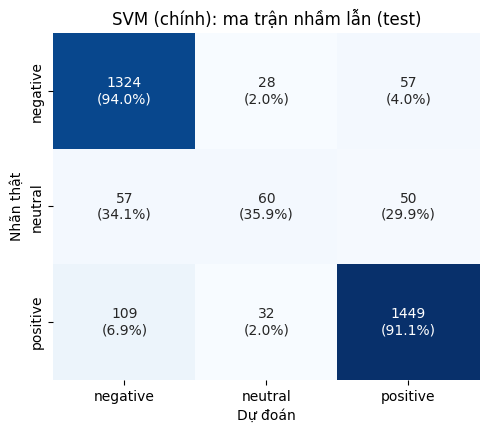


Macro-F1 test = 0.7509 | KTC 95% (bootstrap) = [0.7248, 0.7748]

Đã lưu: ml_best_test_predictions.csv, ml_test_metrics.csv, fig_cm_ml_best_test.png

Số câu sai liên quan neutral: 167
                                                                                                                                                 text_clean    y_true    y_pred
1924                                                                                                                                      đề cương đầy đủ .  positive   neutral
2049                                                            bài tập thầy cho cũng đòi hỏi phải đến lớp , nghe giảng và phải hiểu thật sự mới làm được .   neutral  negative
1421                                                                                                     với lại đặc thù sinh viên trường em nó khác cô ạ .   neutral  negative
965                                                                                                  cảm ơn thầy

In [20]:
import re

# --- 1. Dựng lại 3 mô hình, chỉ fit trên train ---
FINAL = {
    'SVM (chính)': Pipeline([('vec', FEATS['word(1,2)+char_wb(2,5)']()), ('clf', make_svm('balanced', 1.0))]),
    'LR':          Pipeline([('vec', FEATS['word(1,2)+char_wb(2,5)']()), ('clf', make_lr({0: 1, 1: 6, 2: 1}, 10.0))]),
    'NB':          Pipeline([('vec', make_vec(ngram_range=(1, 1))),       ('clf', MultinomialNB(alpha=1.0, fit_prior=False))]),
}
for name, p in FINAL.items():
    p.fit(tr['text_clean'], y_tr)

# --- Kiểm tra: điểm dev của mô hình chính phải khớp ô 7 ---
dev_main = evaluate(y_dv, FINAL['SVM (chính)'].predict(dv['text_clean']))['macro_f1']
print(f'Dev Macro-F1 (mô hình chính): {dev_main:.4f} (kỳ vọng 0.7834)')
assert abs(dev_main - 0.7834) < 5e-4, 'Không khớp ô 7, kiểm tra lại cấu hình'

# --- 2. Chấm test (một lần duy nhất) ---
test_rows, test_pred = [], {}
for name, p in FINAL.items():
    pred = p.predict(te['text_clean'])
    test_pred[name] = pred
    r = evaluate(y_te, pred, name, 'test')
    log_result(r, text_col='text_clean', stage='o8')
    dv_f1 = evaluate(y_dv, p.predict(dv['text_clean']))['macro_f1']
    test_rows.append({**r, 'dev_macro_f1': dv_f1})
tab = pd.DataFrame(test_rows)
cols = ['model', 'macro_f1', 'dev_macro_f1', 'accuracy',
        'P_negative', 'R_negative', 'F1_negative',
        'P_neutral', 'R_neutral', 'F1_neutral',
        'P_positive', 'R_positive', 'F1_positive']
print('\nKết quả trên TEST:')
print(tab[cols].round(4).to_string(index=False))

MAIN = 'SVM (chính)'
print(f'\n=== Báo cáo chi tiết {MAIN} (test) ===')
show_report(y_te, test_pred[MAIN])

# --- 3. Ma trận nhầm lẫn ---
plot_cm(y_te, test_pred[MAIN], f'{MAIN}: ma trận nhầm lẫn (test)',
        path=f'{RESULTS_DIR}/fig_cm_ml_best_test.png')

# --- 4. Khoảng tin cậy bootstrap cho Macro-F1 trên test ---
B = 1000
rng = np.random.default_rng(SEED)
n = len(te)
bs = np.empty(B)
for b in range(B):
    i = rng.integers(0, n, n)
    bs[b] = f1_score(y_te[i], test_pred[MAIN][i], average='macro', labels=LABEL_IDS, zero_division=0)
lo, hi = np.percentile(bs, [2.5, 97.5])
print(f'\nMacro-F1 test = {tab.loc[0, "macro_f1"]:.4f} | KTC 95% (bootstrap) = [{lo:.4f}, {hi:.4f}]')

# --- 5. Lưu dự đoán và bảng số liệu ---
CONTRAST = r'\b(?:nhưng|tuy nhiên|tuy|mặc dù|dù|bên cạnh đó|chỉ có điều|chỉ tiếc|tuy vậy)\b'
pred_df = pd.DataFrame({
    'text_raw':   te['text_raw'],
    'text_clean': te['text_clean'],
    'y_true':     te['sentiment_name'],
    'y_pred':     pd.Series(test_pred[MAIN]).map(ID2NAME),
    'n_words':    te['text_clean'].str.split().str.len(),
    'has_contrast': te['text_clean'].str.contains(CONTRAST, regex=True),
})
pred_df['correct'] = pred_df['y_true'] == pred_df['y_pred']
pred_df.to_csv(f'{RESULTS_DIR}/ml_best_test_predictions.csv', index=False, encoding='utf-8-sig')
tab[cols].round(4).to_csv(f'{RESULTS_DIR}/ml_test_metrics.csv', index=False)
print('\nĐã lưu: ml_best_test_predictions.csv, ml_test_metrics.csv, fig_cm_ml_best_test.png')

# --- Xem nhanh lỗi của lớp neutral ---
err = pred_df[(~pred_df['correct']) & ((pred_df['y_true'] == 'neutral') | (pred_df['y_pred'] == 'neutral'))]
print(f'\nSố câu sai liên quan neutral: {len(err)}')
print(err[['text_clean', 'y_true', 'y_pred']].sample(min(8, len(err)), random_state=SEED).to_string())

## Ô 9. Bảng tổng hợp, phân tích lỗi và nhật ký

Ô cuối của notebook. Ba việc, tất cả chỉ dùng kết quả đã có, **không chọn hay chỉnh mô hình nào nữa**:

1. **Phân tích lỗi trên test** của mô hình chính, theo hai chiều đã đề cập ở ô 8: câu có từ nối đối lập ("nhưng", "tuy nhiên", ...) và độ dài câu. Số liệu thật sẽ cho biết giả thuyết "khen rồi chê gây nhầm" đúng hay sai.
2. **Kiểm định ghép cặp SVM so với LR trên test** (bootstrap), để trả lời câu hỏi còn bỏ ngỏ ở ô 8: SVM hơn LR thật hay chỉ nằm trong nhiễu.
3. **Lưu kết quả và sinh nhật ký** `ml_baseline_log.md`: mọi con số trong nhật ký được tính từ biến của notebook, không gõ tay.

Ngoài ra lưu hai file phục vụ báo cáo: bảng toàn bộ cấu hình trên dev và 50 câu neutral bị đoán sai (để bạn tự phân loại nguyên nhân lỗi). Các file chứa nội dung câu phản hồi nên chỉ để trên Drive, không đưa lên GitHub.

In [21]:
# ===== A. Phân tích lỗi trên test (mô hình chính) =====
MAIN = 'SVM (chính)'
pe = pred_df.copy()
pe['err'] = ~pe['correct']
pe['len_bin'] = pd.cut(pe['n_words'], [0, 5, 10, 20, np.inf], labels=['<=5', '6-10', '11-20', '>20'])

def grp_stats(g):
    out = {'n': len(g), 'acc': g['correct'].mean()}
    for lab in LABELS:
        m = g['y_true'] == lab
        out[f'n_{lab}'] = int(m.sum())
        out[f'R_{lab}'] = g.loc[m, 'correct'].mean() if m.any() else np.nan
    return pd.Series(out)

by_contrast = pe.groupby('has_contrast').apply(grp_stats)
by_len      = pe.groupby('len_bin', observed=True).apply(grp_stats)

print('Theo có/không từ nối đối lập (acc, recall từng lớp):')
print(by_contrast.round(3).to_string())
print('\nPhân bố nhãn thật trong từng nhóm (%):')
print((pd.crosstab(pe['has_contrast'], pe['y_true'], normalize='index')[LABELS] * 100).round(1).to_string())
print('\nTheo độ dài câu (số token của text_clean):')
print(by_len.round(3).to_string())

pairs = (pe[pe['err']].groupby(['y_true', 'y_pred']).size().sort_values(ascending=False).rename('n_loi').reset_index())
print('\nCác cặp nhầm lẫn (nhãn thật -> dự đoán):')
print(pairs.to_string(index=False))

# 50 câu neutral bị đoán sai để tự phân loại nguyên nhân (chỉ để trên Drive)
neu_err = pe[(pe['y_true'] == 'neutral') & pe['err']]
neu_out = (neu_err.sample(min(50, len(neu_err)), random_state=SEED)[['text_clean', 'y_pred']]
           .assign(error_type=''))        # điền: mơ hồ / mô tả-đề xuất / khen chê lẫn / khác
neu_out.to_csv(f'{RESULTS_DIR}/ml_neutral_errors_to_label.csv', index=False, encoding='utf-8-sig')
print(f'\nĐã lưu {len(neu_out)} câu neutral sai (trên tổng {len(neu_err)}) để phân loại tay.')

# ===== B. Bootstrap ghép cặp trên test: SVM chính vs LR =====
B = 1000
rng = np.random.default_rng(SEED)
n = len(te)
p_s, p_l = test_pred[MAIN], test_pred['LR']
bs_main, bs_diff = np.empty(B), np.empty(B)
for b in range(B):
    i = rng.integers(0, n, n)
    f_s = f1_score(y_te[i], p_s[i], average='macro', labels=LABEL_IDS, zero_division=0)
    f_l = f1_score(y_te[i], p_l[i], average='macro', labels=LABEL_IDS, zero_division=0)
    bs_main[b], bs_diff[b] = f_s, f_s - f_l
ci_lo, ci_hi = np.percentile(bs_main, [2.5, 97.5])
d_lo, d_hi   = np.percentile(bs_diff, [2.5, 97.5])
print(f'\nMacro-F1 test SVM = {f1_score(y_te, p_s, average="macro"):.4f} | KTC 95% [{ci_lo:.4f}, {ci_hi:.4f}] (phải khớp ô 8)')
print(f'SVM - LR trên test: trung bình {bs_diff.mean():+.4f} | KTC 95% [{d_lo:+.4f}, {d_hi:+.4f}] '
      f'| P(SVM > LR) = {(bs_diff > 0).mean():.2f}')

# ===== C. Bảng tổng hợp và lưu file =====
all_dev = pd.DataFrame([r for r in RESULTS if r['split'] == 'dev'])
keep = [c for c in ['model', 'stage', 'text_col', 'feat', 'clf_name', 'C', 'cw_name', 'macro_f1', 'accuracy',
                    'P_neutral', 'R_neutral', 'F1_neutral', 'F1_negative', 'F1_positive', 'fit_sec'] if c in all_dev.columns]
all_dev = all_dev[keep].sort_values('macro_f1', ascending=False)
all_dev.round(4).to_csv(f'{RESULTS_DIR}/ml_all_dev_results.csv', index=False, encoding='utf-8-sig')
print(f'\nĐã lưu ml_all_dev_results.csv ({len(all_dev)} cấu hình trên dev). Top 8:')
print(all_dev[['model', 'macro_f1', 'F1_neutral']].head(8).round(4).to_string(index=False))

# ===== D. Nhật ký =====
def to_md(df):
    cols = list(df.columns)
    lines = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '---|' * len(cols)]
    for _, r in df.iterrows():
        cells = []
        for c in cols:
            v = r[c]
            if isinstance(v, (float, np.floating)):
                cells.append('' if np.isnan(v) else (f'{v:.0f}' if str(c).startswith('n') else f'{v:.3f}'))
            else:
                cells.append(str(v))
        lines.append('| ' + ' | '.join(lines_ := cells) + ' |')
    return '\n'.join(lines)

def dev_f1(name):
    return next(r['macro_f1'] for r in RESULTS if r['model'] == name and r['split'] == 'dev')

m_row  = tab[tab['model'] == MAIN].iloc[0]
test_md = to_md(tab[['model', 'macro_f1', 'accuracy', 'F1_negative', 'F1_neutral', 'F1_positive',
                     'P_neutral', 'R_neutral']].reset_index(drop=True))
feat_line = '; '.join(f"{f} {dev_f1(f'{f} + SVM-bal'):.4f}" for f in FEATS)
cv_def = cv[(cv['clf'] == 'SVM') & cv['is_default']]['cv_mean'].iloc[0]
svm_grid = grid[grid['clf'] == 'SVM']['macro_f1']
c_t, c_f = by_contrast.loc[True], by_contrast.loc[False]
len_md = to_md(by_len.reset_index()[['len_bin', 'n', 'acc', 'R_neutral']].rename(columns={'len_bin': 'do_dai'}))
top_pairs = '; '.join(f"{r.y_true}→{r.y_pred}: {r.n_loi}" for r in pairs.head(4).itertuples())

log = f"""# Nhật ký baseline ML truyền thống: Project 1 (UIT-VSFC)

## 1. Thiết lập
- Dữ liệu: `data_clean.csv`, train {len(tr)} / dev {len(dv)} / test {len(te)}; neutral: {int((y_tr==1).sum())} / {int((y_dv==1).sum())} / {int((y_te==1).sum())} câu.
- Quy tắc: chọn mô hình chỉ bằng dev và cross-validation 5 fold trên train; test chấm một lần (ô 8).
- Metric chính Macro-F1, kèm Precision / Recall / F1 từng lớp và ma trận nhầm lẫn. Seed = {SEED}.

## 2. Các quyết định (dev, Macro-F1)
| Bước | Kết quả | Quyết định |
|---|---|---|
| Class weight (ô 3-4) | LR {dev_f1('TFIDF-uni + LR'):.4f} → {dev_f1('TFIDF-uni + LR (balanced)'):.4f}; SVM {dev_f1('TFIDF-uni + SVM'):.4f} → {dev_f1('TFIDF-uni + SVM (balanced)'):.4f} | Dùng trọng số lớp: không dùng thì Recall neutral chỉ ~0,15-0,18 |
| Bộ phân loại, unigram (ô 4) | SVM-bal {dev_f1('TFIDF-uni + SVM (balanced)'):.4f}; LR-bal {dev_f1('TFIDF-uni + LR (balanced)'):.4f}; NB {dev_f1('TFIDF-uni + MultinomialNB (fit_prior=F)'):.4f} | SVM dẫn đầu; NB làm mốc thấp |
| Đặc trưng, SVM-bal (ô 5) | {feat_line} | Chọn `word(1,2)+char_wb(2,5)`: tốt nhất ở cả SVM và LR; trigram không giúp |
| text_clean và text_seg (ô 6) | Chênh (seg − clean) từ {cmp6['diff'].min():+.4f} đến {cmp6['diff'].max():+.4f}, hướng không nhất quán; KTC bootstrap của SVM đều chứa 0 | Giữ `text_clean` (không cần VnCoreNLP khi triển khai) |
| Tinh chỉnh (ô 7) | Lưới SVM trên dev {svm_grid.min():.4f}-{svm_grid.max():.4f}; CV của mặc định = {cv_def:.4f} | Giữ mặc định (`C`={BEST['C']}, `{BEST['cw_name']}`): xếp đầu theo CV, các ô lưới trên dev chỉ là nhiễu |

## 3. Kết quả trên test
{test_md}

- Mô hình chính {MAIN}: Macro-F1 = {m_row['macro_f1']:.4f}, KTC 95% (bootstrap) = [{ci_lo:.4f}, {ci_hi:.4f}]; dev = {m_row['dev_macro_f1']:.4f}, CV = {cv_def:.4f}.
- SVM − LR trên test: {bs_diff.mean():+.4f}, KTC 95% [{d_lo:+.4f}, {d_hi:+.4f}], P(SVM > LR) = {(bs_diff > 0).mean():.2f}.
- Ma trận nhầm lẫn: `fig_cm_ml_best_test.png`. Các cặp nhầm nhiều nhất: {top_pairs}.

## 4. Phân tích lỗi (test, mô hình chính)
- Câu có từ nối đối lập: {int(c_t['n'])} câu, accuracy {c_t['acc']:.3f}; còn lại: {int(c_f['n'])} câu, accuracy {c_f['acc']:.3f}.
- Theo độ dài câu:

{len_md}

- Lớp neutral: Recall {m_row['R_neutral']:.3f}, Precision {m_row['P_neutral']:.3f}; {len(neu_err)} trên {int((y_te==1).sum())} câu neutral bị đoán sai (file `ml_neutral_errors_to_label.csv` để phân loại nguyên nhân).

## 5. Hạn chế
- Neutral dev chỉ {int((y_dv==1).sum())} câu: điểm dev lạc quan (đã dùng để chọn đặc trưng) và dao động mạnh; điểm CV và test là ước lượng gần thực tế hơn.
- Test cũng chỉ có {int((y_te==1).sum())} câu neutral; KTC bootstrap chỉ phản ánh sai số lấy mẫu của test, chưa tính biến thiên do huấn luyện.
- Chỉ thử các bộ phân loại tuyến tính và Naive Bayes, đặc trưng TF-IDF; chưa dùng embedding.
- Nhãn neutral có phần mơ hồ (ví dụ câu cảm ơn bị gán nhãn không nhất quán), nên một phần trần của mô hình đến từ nhãn.

## 6. Việc để lại
- Huấn luyện BiLSTM và PhoBERT trên cùng split, dùng cùng metric và cùng cách báo KTC để so sánh công bằng với bảng ở mục 3.
- Phân loại tay 50 câu neutral bị sai để mô tả nguyên nhân lỗi trong báo cáo.
"""
with open(f'{RESULTS_DIR}/ml_baseline_log.md', 'w', encoding='utf-8') as f:
    f.write(log)
print(f'\nĐã lưu ml_baseline_log.md\n')
print(log)

Theo có/không từ nối đối lập (acc, recall từng lớp):
                   n    acc  n_negative  R_negative  n_neutral  R_neutral  n_positive  R_positive
has_contrast                                                                                     
False         3027.0  0.899      1303.0       0.939      157.0      0.376      1567.0       0.918
True           139.0  0.806       106.0       0.943       10.0      0.100        23.0       0.478

Phân bố nhãn thật trong từng nhóm (%):
y_true        negative  neutral  positive
has_contrast                             
False             43.0      5.2      51.8
True              76.3      7.2      16.5

Theo độ dài câu (số token của text_clean):
              n    acc  n_negative  R_negative  n_neutral  R_neutral  n_positive  R_positive
len_bin                                                                                     
<=5       310.0  0.845        97.0       0.907       56.0      0.589       157.0       0.898
6-10     1133.0  0.909  